Introduction:

Since the 18th century, atmospheric carbon dioxide (CO2) concentrations have increased from a baseline of 276ppm to 427ppm. The global oceans absorb and dissolve CO2, which leads to increases in acidity from the reaction with water creating carbonic acid. Excess heat trapped in the atmosphere by the greenhouse effect is also absorbed. Warmer oceans have a decreased ability to retain dissolved gases such as oxygen. With the oceans absorbing more than 30% of anthropogenic CO2 and over 90% of excess planetary heat, the risk that ocean acidification and decreased dissolved oxygen levels pose grow each year. Acute ocean acidification and hypoxia events impact coastal ecosystems heavily, with immobile and calcifying organisms being impacted the most.

While satellites can measure surface biogeochemistry, they struggle to resolve ocean floor conditions. In-situ observational data of sea floor dissolved oxygen and saturated aragonite is expensive to collect and sparse. Additionally, it is impossible to forecast regional conditions and hypoxia or acidification events alone. 

This is why it is important to develop and validate models to help inform regional fisheries and ecosystem management efforts. The Modular Ocean Model - Carbon, Ocean Biogeochemistry and Lower Trophics (MOM6-COBALT) is a coupled physics-biogeochemistry model that may be used for such forecasting.  



Validating model outputs requires direct comparisons between past observations and model hindcasts - model simulations of the past using baseline conditions. The following workflow details the comparison of observational data from NOAA Ecomonitoring vessels, demursal sea gliders, Ocean Observation Initiative measurements, EMOLT lobster cage, and Copperarative Commercial Fisheries Research Fleet data.

The first step to creating an operable python workflow for this comparison is importing the correct modules into a kernel and setting up Paths for export: 

In [ ]:
#Very first step is to import these modules and libraries into the satprocessing kernel
import numpy as np
import dask as ds
import earthaccess as ea
import xarray as xr
import sys
import os
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import requests
import pandas as pd
import PyCO2SYS as pyco2
import cartopy.crs as ccrs          # ccrs handles projections
import cartopy.feature as cfeature  # cfeature handles land, ocean, coastlines
import cartopy
from shapely.ops import unary_union
import cartopy.feature as cfeature
from datetime import date
from scipy.spatial import KDTree
from datasets import Dataset
import geopandas as gpd
import rioxarray
from shapely.geometry import mapping
from setuptools import setup, find_packages
import statsmodels.api as sm
import seaborn as sns





print("module import success")


sys.path.append(r'C:\\Users\\edmund.gable\\Documents\\Hollings_2026\\RESOURCES\\python\\utilities\\bootstrap\\')
print("path import success")

import pprint
from environment import bootstrap_environment  
pprint.pprint(bootstrap_environment(preferred="edmund_gable"))
print("success")

from utilities.bootstrap.environment import bootstrap_environment
env = bootstrap_environment(preferred="edmund.gable")
env
print("utilities import success")

#Before this next step, install the library 'resource': conda install -c conda-forge resource
from utilities import get_dates, get_source_file_dates, find_text
find_text("stats")

from utilities import get_prod_files 
get_prod_files("DO", period="DOY")
#"DOY" is climatological 'day of year
#'W' is climatological weekly files

from pathlib import Path

root = Path(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026")
raw_data = Path(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Raw_Data")
model_data = Path(r"Z:\\MOM6\Hindcasts\\BTM-O2-REGRID")
processed_data=Path(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Processed_Data\comparison")
code_path = Path(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\code")
sys.path.append(str(code_path))
import functions as f

dsg = xr.open_dataset(r"Z:\MOM6\V0.0\SOURCE\NES_9KM_HINDCAST\ARAG\CEFI-ARAG-HINDCAST-20070101.nc")
ny, nx = len(dsg.lat), len(dsg.lon)
grid_id_matrix = np.array([[f"{y},{x}" for x in range(nx)] for y in range(ny)], dtype=str)
grid_ds = dsg.assign_coords(grid_id=(['lat', 'lon'], grid_id_matrix))


c:\Users\edmund.gable\.conda\envs\satprocessing\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


module import success
path import success
⚠ Unrecognized preferred label 'edmund_gable'. Valid options: ['NECMAC04363461.local', 'nefscsatdata', 'guihyde', 'Mac.localdomain', 'gdavis', 'egable']
{'dataset_path': WindowsPath('C:/Users/edmund.gable/Documents/Hollings_2026/DATASETS'),
 'hostname': 'NECL04363598',
 'lookuptable_path': WindowsPath('C:/Users/edmund.gable/Documents/Hollings_2026/RESOURCES/workflow_resources/lookuptables'),
 'metadata_path': WindowsPath('C:/Users/edmund.gable/Documents/Hollings_2026/RESOURCES/workflow_resources/metadata'),
 'project_root': WindowsPath('C:/Users/edmund.gable/Documents/Hollings_2026/RESOURCES/python'),
 'python_path': WindowsPath('C:/Users/edmund.gable/Documents/Hollings_2026/RESOURCES/python'),
 'satlogs_path': WindowsPath('C:/Users/edmund.gable/Documents/Hollings_2026/RESOURCES/logs/satprocessing'),
 'timestamp': datetime.datetime(2026, 7, 24, 9, 12, 20, 594987),
 'utilities_path': WindowsPath('C:/Users/edmund.gable/Documents/Hollings_2026/RES

C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\code\functions.py:976: SyntaxWarning: invalid escape sequence '\D'
  f"Mean $\Delta$: {mean_delta:+.3f} mg/L\n"
C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\code\functions.py:977: SyntaxWarning: invalid escape sequence '\D'
  f"Median $\Delta$: {median_delta:+.3f} mg/L\n"
C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\code\functions.py:978: SyntaxWarning: invalid escape sequence '\m'
  f"Model $\mu$: {global_mean:.3f} mg/L\n"
C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\code\functions.py:979: SyntaxWarning: invalid escape sequence '\m'
  f"Obs $\mu$: {obs_mean:.3f} mg/L\n"
C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\code\functions.py:980: SyntaxWarning: invalid escape sequence '\s'
  f"Obs $\sigma$: {obs_std:.3f} mg/L\n"
C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\code\functions.py:981: SyntaxW

To compare the MOM6-COBALT outputs with raw data, first get an index of the model grids...

In [9]:
# 1. create the MOM6-COBALT grid df from one of the hindcast data files. 

ds=xr.open_dataset(r"Z:\MOM6\Hindcasts\BTM-O2-REGRID\2005\03\CEFI-BTM_O2-HINDCAST-20050321.nc")
ds
y_indices=xr.DataArray(np.arange(len(ds.lat)),dims=["lat"])
x_indices=xr.DataArray(np.arange(len(ds.lon)),dims=['lon'])

#broadcat x and y coordinates from lon and lat, and put into lat,lon format
y_grid, x_grid = xr.broadcast(y_indices, x_indices)

grid_ids=xr.apply_ufunc(
    lambda y,x: f'{y},{x}',
    y_grid, x_grid,
    vectorize=True,
    dask="allowed"
)

#create the grid id     
grid_ds=ds.assign_coords(grid_id=(['lat','lon'], grid_ids.values))



df_mom6_raw=grid_ds.to_dataframe()
df_mom6_raw=df_mom6_raw.reset_index()
print(df_mom6_raw.columns.to_list())
grid_extent = df_mom6_raw[["lat", "lon", 'grid_id']].drop_duplicates().reset_index(drop=True)


# 3. Save this file so you don't have to keep rebuilding it
export_path=(r"C:\\Users\\edmund.gable\\Documents\\Hollings_2026\\GitHub\\MOM6-COBALT_2026\\data\\Index\\MOM6_Grid_Extent.csv")
grid_extent.to_csv(export_path, date_format='%Y-%m-%d %H:%M:%S', index=False)




dsg=grid_extent.set_index(['lat','lon']).to_xarray()
print(dsg)


['time', 'lat', 'lon', 'btm_o2', 'grid_id']
<xarray.Dataset> Size: 1MB
Dimensions:  (lat: 413, lon: 385)
Coordinates:
  * lat      (lat) float64 3kB 22.53 22.59 22.65 22.71 ... 48.25 48.31 48.37
  * lon      (lon) float64 3kB -82.47 -82.39 -82.31 ... -51.65 -51.57 -51.49
Data variables:
    grid_id  (lat, lon) object 1MB '0,0' '0,1' '0,2' ... '412,383' '412,384'


Next, open a raw observational file (ex: downloaded from an ERRDAP search) and concatonate it with any others 

In [20]:
#1. Open the observational data files 

Fishbot=f.open_file(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Raw Data\Fishbot\ondeckdata_erddap_4319_ff7a_72eb_8faf_65b1_f215.nc")
Fishbot=Fishbot.reset_index()
ECOMON=f.open_file(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Raw Data\Vessels\ECOMON.nc")
ECOMON=ECOMON[ECOMON['cruise_id']!='HB2101'] #removed this cruise because the oxygen detector malfunctioned
print(Fishbot.columns.to_list())
Fishbot['bottom_depth']=Fishbot['depth']
Fishbot['cruise_id']=Fishbot['data_provider']

#make sure duplicate data will not be present
Fishbot=Fishbot[Fishbot['cruise_id']!='ECOMON']
Fishbot.drop(columns=['data_provider'], inplace=True)
Fishbot.dropna(subset=['dissolved_oxygen'], inplace=True)
ECOMON['time'] = pd.to_datetime(ECOMON['UTC_DATETIME'], errors='coerce')
ECOMON.drop(columns=['UTC_DATETIME'], inplace=True)
#print(Fishbot.columns.to_list())
ECOMON=f.classify_stress(ECOMON, 'dissolved_oxygen', 'DO_status')
merged_df = pd.concat([Fishbot, ECOMON], ignore_index=True)
merged_df['time'] = pd.to_datetime(merged_df['time'], errors='coerce')
merged_df = merged_df.dropna(subset=['time'])
merged_df['time'] = merged_df['time'].dt.normalize() + pd.Timedelta(hours=12)
print(merged_df.columns.to_list())


Available flattened columns: ['row', 'time', 'dissolved_oxygen', 'data_provider', 'depth', 'latitude', 'longitude']
Available flattened columns: ['row', 'UTC_DATETIME', 'latitude', 'longitude', 'depth', 'dissolved_oxygen', 'cruise_id', 'bottom_depth']
['index', 'row', 'time', 'dissolved_oxygen', 'data_provider', 'depth', 'latitude', 'longitude']
['index', 'row', 'time', 'dissolved_oxygen', 'depth', 'latitude', 'longitude', 'bottom_depth', 'cruise_id', 'DO_status']


In [21]:
Fishbot.to_csv(processed_data / "Fishbot.csv", date_format='%Y-%m-%d %H:%M:%S', index=False)


The next step is to prepare the dataset by matching observational data points to a grid and averaging them by grid and day. Use the specific OA/DO perpare_xx_df function for this, or prepare_df_no_depth if the dataset is already filtered to the bottom. 

In [22]:
#Read in the grid extent csv you made previously 
mom6_grid_df = pd.read_csv(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Index\MOM6_Grid_Extent.csv")

#use this grid to match observational data
"""prepare_DO_df(df, DO_col, id_col, obs_depth_col, bottom_depth_col, lat_col, lon_col, time_col, mom6_grid_df, battery_col=None):"""
dfp=f.prepare_DO_df(merged_df, 'dissolved_oxygen', 'cruise_id', 'depth', 'bottom_depth', 'latitude', 'longitude', 'time', mom6_grid_df)
#dfp.to_csv(processed_data /  "Concat_MOM6_grid_matched.csv")
dfp

,id,lat,lon,obs_depth,bottom_depth,dissolved_oxygen,DO_status,grid_id,matched_time,matched_lat,matched_lon
0,DEL0909,39.974998,-72.511703,61.500000,67.0,7.100000,Oxygenated,"278,123",2009-08-18 12:00:00,39.966708,-72.545378
1,DEL0909,40.058300,-72.838303,49.099998,52.0,6.025000,Oxygenated,"279,119",2009-08-18 12:00:00,40.029446,-72.868081
2,DEL0909,40.070000,-72.826698,50.099998,55.0,6.100000,Oxygenated,"280,120",2009-08-18 12:00:00,40.092184,-72.787405
3,DEL0909,40.098301,-71.758301,76.400002,82.0,6.100000,Oxygenated,"280,133",2009-08-18 12:00:00,40.092184,-71.738622
4,DEL0909,39.013302,-73.816704,33.700001,37.0,6.200000,Oxygenated,"263,107",2009-08-19 12:00:00,39.025637,-73.836189
...,...,...,...,...,...,...,...,...,...,...,...
32788,OOI,35.740658,-74.842468,98.000000,98.0,7.588453,Oxygenated,"211,95",2026-07-19 12:00:00,35.763256,-74.804297
32789,OOI,35.980209,-75.092690,27.000000,27.0,10.072810,Oxygenated,"214,91",2026-07-19 12:00:00,35.951470,-75.126999
32790,OOI,36.183918,-74.797600,115.000000,115.0,7.730409,Oxygenated,"218,95",2026-07-19 12:00:00,36.202422,-74.804297
32791,CFRF,41.409405,-71.387825,28.000000,28.0,5.195098,Oxygenated,"301,137",2026-07-19 12:00:00,41.409684,-71.415919


Once this dataframe is exported, MOM6-COBALT data can be matched to it and run for analysis. This will take some time depending on how much data you have (about 1-3 seconds per data point)

In [23]:
CONCAT=f.load_combined_DO_mom6_data(dfp, model_data, mom6_var='btm_o2', grid_ds=grid_ds)
CONCAT.to_csv(processed_data / 'CONCAT_MOM6_3x3x3_prepped.csv')

Processing 3991 unique dates...


Next, classify the stress of the model outputs:

In [2]:
CONCAT=pd.read_csv(processed_data / 'CONCAT_MOM6_3x3x3_prepped.csv')
final=f.classify_stress(CONCAT, 'closest_model_val', 'model_DO_status')
final= f.delta_difference(final, 'dissolved_oxygen')
final.to_csv(processed_data / 'CONCAT_MOM6_3x3x3_comparison.csv')

Mean of delta difference between model 3x3x3 grid data and observational data is: 0.205171
Mean of delta difference between model exact grid data and observational data is: 0.195564
Global RMSE (3x3x3 grid vs obs) between model and observations is: 1.1808
Global RMSE (Exact point vs Obs): 1.5103
-> Calculated using 18212 valid exact points (out of 18444 total pairs).
Calculated Observational Mean: 6.8271
Calculated Model Global Mean: 7.0681
Calculated Global Std Dev: 1.5125
Model grid overestimates the data 56.35436998481891 percent of the time
Model grid underestimates the data 43.645630015181084 percent of the time
When overestimating, the average excess oxygen is: 0.8545
When underestimating, the average deficit oxygen is: -0.6332
Real-World Observational STD: 1.6559
Model Global STD: 1.5125
Model-to-Observation Variance Ratio: 0.91
Model RSR: (0.7131149423472916)

GENERAL STRESS DETECTION METRICS (Binary: Stress vs No Stress)
Total observations showing stressed conditions: 2935
Tot

Finally, append season, depth, and region to the dataset:

In [3]:
df=f.classify(final, 'bottom_depth', lat_col='matched_lat', lon_col='matched_lon')
df.to_csv(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Processed_Data\comparison\complete\CONCAT_MOM6_3x3x3_comparison_classified.csv", index=False)

The dataframe is now ready for figure creation and data analysis. 

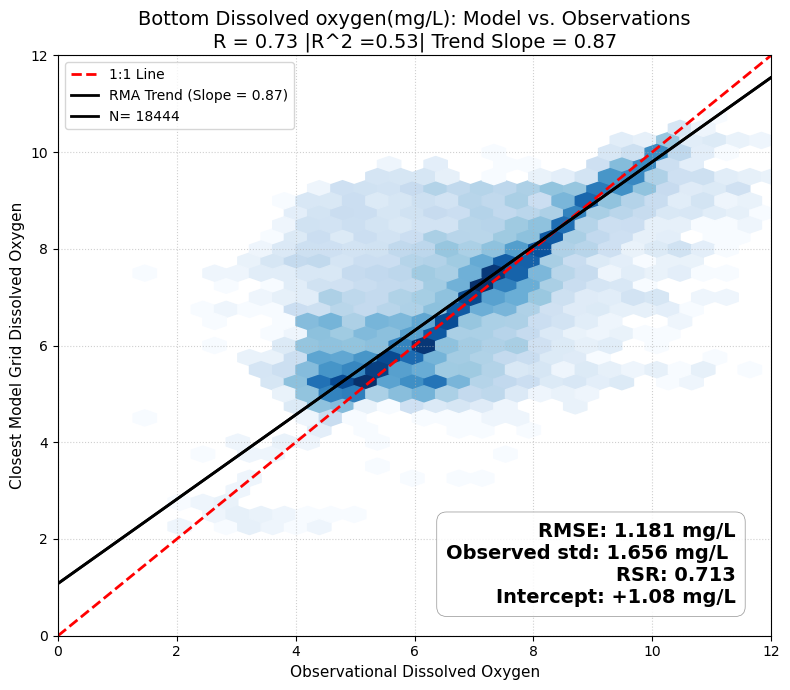

{'slope': 0.8718686661168009,
 'r_value': 0.7265704398934189,
 'N_samples': 18444}

In [4]:
df=pd.read_csv(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Processed_Data\comparison\complete\CONCAT_MOM6_3x3x3_comparison_classified.csv")
f.hexplot(df, 'dissolved_oxygen')

Do the same for aragonite

In [8]:
mom6_grid_df = pd.read_csv(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Index\MOM6_Grid_Extent.csv")
Gliders=f.open_file(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Raw Data\New folder\glider_based_bottom_OA_data_2019_2025.nc")
Vessels=f.open_file(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Raw Data\vessel_bottom_OA\vessel_based_bottom_OA_data_2007_2024.nc")
Gliders['id']=Gliders['deployment']
Gliders.drop(columns=['deployment'], inplace=True)
Vessels['id']=Vessels['data_source']
Vessels.drop(columns=['data_source'], inplace=True)
Gliders=Gliders.reset_index()
Vessels=Vessels.reset_index()
Gliders['time'] = pd.to_datetime(Gliders['time'], errors='coerce')
Vessels=f.classify_stress(Vessels, 'omega_bottom', 'arag_status')
Gliders=f.classify_stress(Gliders, 'omega_bottom', 'arag_status')
merged_df = pd.concat([Gliders, Vessels], ignore_index=True)
print(merged_df.columns.to_list())
merged_df.to_csv(processed_data / 'OA_CONCAT.csv')



merged_df["time"] = pd.to_datetime(merged_df['time'])
dfp=f.prepare_OA_df(merged_df, 'omega_bottom', 'id', 'depth', 'bottom_depth', 'lat', 'lon', 'time', mom6_grid_df)
dfp.to_csv(processed_data / 'OA_prepared.csv')

Available flattened columns: ['time', 'deployment', 'lat', 'lon', 'depth', 'bottom_depth', 'pH_bottom', 'omega_bottom', 'temperature_bottom']
Available flattened columns: ['time', 'data_source', 'cruise', 'obs_type', 'accession', 'lat', 'lon', 'depth', 'bottom_depth', 'pH_bottom', 'omega_bottom', 'temperature_bottom']
['level_0', 'index', 'time', 'lat', 'lon', 'depth', 'bottom_depth', 'pH_bottom', 'omega_bottom', 'temperature_bottom', 'id', 'arag_status', 'cruise', 'obs_type', 'accession']


In [ ]:
model_data = Path(r"Z:\\MOM6\Hindcasts\\BTM-O2-REGRID")

df=pd.read_csv(processed_data / 'OA_prepared.csv')
df=f.load_combined_OA_mom6_data(df, model_data, grid_ds=None)
df.to_csv(processed_data / 'OA_MOM6_3x3x3_comparison.csv')

C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\code\functions.py:976: SyntaxWarning: invalid escape sequence '\D'
  f"Mean $\Delta$: {mean_delta:+.3f} mg/L\n"
C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\code\functions.py:977: SyntaxWarning: invalid escape sequence '\D'
  f"Median $\Delta$: {median_delta:+.3f} mg/L\n"
C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\code\functions.py:978: SyntaxWarning: invalid escape sequence '\m'
  f"Model $\mu$: {global_mean:.3f} mg/L\n"
C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\code\functions.py:979: SyntaxWarning: invalid escape sequence '\m'
  f"Obs $\mu$: {obs_mean:.3f} mg/L\n"
C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\code\functions.py:980: SyntaxWarning: invalid escape sequence '\s'
  f"Obs $\sigma$: {obs_std:.3f} mg/L\n"
C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\code\functions.py:981: SyntaxW

FileNotFoundError: Missing NetCDF files in Z:\MOM6\Hindcasts\BTM-O2-REGRID

In [ ]:
df=f.classify(df, 'bottom_depth', lat_col='matched_lat', lon_col='matched_lon')
df.to_csv(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Processed_Data\comparison\complete\OA_MOM6_3x3x3_comparison_classified.csv", index=False)

Now that the data for DO and OA are processed, figures can be created